# 02: Target Extraction

### Executive Summary & Decision Log

This notebook develops the ground-truth target extraction algorithm that summarizes continuous 5-minute net load into the 4-dimensional target vector: ramp start time ($t_{\text{start}}$), capacity-normalized magnitude ($\Delta MW_{\text{norm}}$), duration ($\Delta t$), and peak ramp speed ($S_{\max}$).

#### Key Decisions
1. **Event Qualification Gate**: Forcing ramp segmentation on dark, stormy days introduces severe label noise. We established a 12:00 PM operational gate: observed morning peak solar penetration ($P_{\text{solar}} / P_{\text{gross}}$) between 10:00 AM and 12:00 PM must reach at least 20%. Non-qualifying days are flagged as "Standard Demand Days," decoupling human lighting/cooking loads from solar collapse.
2. **Noise Filtering vs. Changepoint Detection**: Tested standard offline changepoint detection (PELT). PELT assumes piecewise-constant regimes, which severely over-segmented smooth solar inflections into disconnected micro-ramps during summer thunderstorm squalls. Implemented a 35-minute Savitzky-Golay polynomial filter (window = 7 intervals, order = 2) to eliminate cloud noise while preserving continuous inflection geometry.
3. **The 10% Solar Decay Trough**: Rigid astronomical zenith lockouts (e.g. zenith > 65°) artificially delayed onset detection by up to 2.5 hours in spring. We anchored the trough search to the physical descent of solar generation, locking out onset points until solar generation drops 10% below daily peak. This naturally tracks seasonal solar elevation (2:40 PM summer DST vs. 12:50 PM winter).
4. **Fleet Growth Normalization**: Multi-year solar capacity additions mean raw megawatt ramps are non-stationary. Extrapolated annual ISO-NE CELT reports to monthly resolution and normalized ramp height by contemporaneous total solar capacity, keeping targets stationary from 2021 through 2026.
5. **Production Refactoring**: Ground-truth target logic was extracted to:
   - `src/targets/qualify.py`: 12:00 PM qualification gate.
   - `src/targets/target.py`: Savitzky-Golay filtering and 4D target vector extraction.


*(Empirical curve fitting, changepoint comparisons, and boundary prototypes below)*


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
### Event Qualification ###
####### Only Looking at days that have meaningful amount of solar generation

In [3]:
df = pd.read_parquet('data/processed/telemetry_5min.parquet')

Text(0.5, 0.98, 'Solar Penetration Histogram')

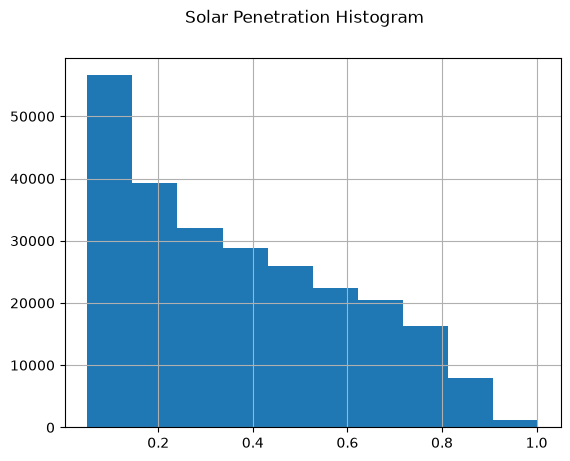

In [8]:
df[df['solar_capacity_factor'] >0.05]['solar_capacity_factor'].hist()#.plot(kind = 'hist', title ='Solar Penetration Histogram')
plt.suptitle("Solar Penetration Histogram")

In [9]:
df.head()

,interval_start_local,interval_end_local,interval_start_utc,interval_end_utc,net_load,reported_load,utility_solar,utility_wind,btm_solar,gross_demand,CELT_BTM_CAPACITY_MW,CELT_UTILITY_CAPACITY_MW,TOTAL_SOLAR_CAPACITY_MW,solar_capacity_factor,solar_zenith,clearsky_ghi
0,2021-01-01 00:00:00-05:00,2021-01-01 00:05:00-05:00,2021-01-01 05:00:00+00:00,2021-01-01 05:05:00+00:00,11463.134,12255.134,0.0,792.0,0.0,12255.134,2393.830137,1666.821918,4060.652055,0.0,160.623899,0.0
1,2021-01-01 00:05:00-05:00,2021-01-01 00:10:00-05:00,2021-01-01 05:05:00+00:00,2021-01-01 05:10:00+00:00,11413.755,12209.755,0.0,796.0,0.0,12209.755,2393.830137,1666.821918,4060.652055,0.0,160.492458,0.0
2,2021-01-01 00:10:00-05:00,2021-01-01 00:15:00-05:00,2021-01-01 05:10:00+00:00,2021-01-01 05:15:00+00:00,11401.268,12193.268,0.0,792.0,0.0,12193.268,2393.830137,1666.821918,4060.652055,0.0,160.306800,0.0
3,2021-01-01 00:15:00-05:00,2021-01-01 00:20:00-05:00,2021-01-01 05:15:00+00:00,2021-01-01 05:20:00+00:00,11350.530,12138.530,0.0,788.0,0.0,12138.530,2393.830137,1666.821918,4060.652055,0.0,160.068465,0.0
4,2021-01-01 00:20:00-05:00,2021-01-01 00:25:00-05:00,2021-01-01 05:20:00+00:00,2021-01-01 05:25:00+00:00,11286.175,12062.675,0.0,776.5,0.0,12062.675,2393.830137,1666.821918,4060.652055,0.0,159.779349,0.0


In [ ]:
# Total solar output
df["total_solar"] = df["btm_solar"] + df["utility_solar"]

# Theoretical clear-sky capacity factor baseline (scaled to 1,000 W/m² STC)

expected_clear_cf = (df["clearsky_ghi"] / 1000.0) 
df["kt"] = (df["solar_capacity_factor"] / expected_clear_cf).clip(0, 1.5)

df['solar_penetration'] = df['total_solar']/df['gross_demand']

#Filter for morning evaluation window: 10:00 AM to 12:00 PM Eastern
morning_mask = (df["interval_start_local"].dt.hour >= 10) & (
    df["interval_start_local"].dt.hour < 12
)
morning_df = df[morning_mask].copy()


In [50]:
morning_df["date"] = morning_df["interval_start_local"].dt.date

daily_summary = (
    morning_df.groupby("date")
    .agg(
        morning_peak_mw=("total_solar", "max"),
        morning_peak_kt=("kt", "max"),
        morning_peak_cf=("solar_capacity_factor", "max"),
        morning_peak_sp=('solar_penetration',"max")
    )
    .reset_index()
)

# Apply gate:
daily_summary["qualifies"] = (daily_summary["morning_peak_sp"] >= 0.20)


# Check overall and seasonal qualification counts
print("Total days:", len(daily_summary))
print(f"Qualifying days: {daily_summary['qualifies'].sum()} ({daily_summary['qualifies'].mean():.1%})")


Total days: 1826
Qualifying days: 940 (51.5%)


<Axes: ylabel='Frequency'>

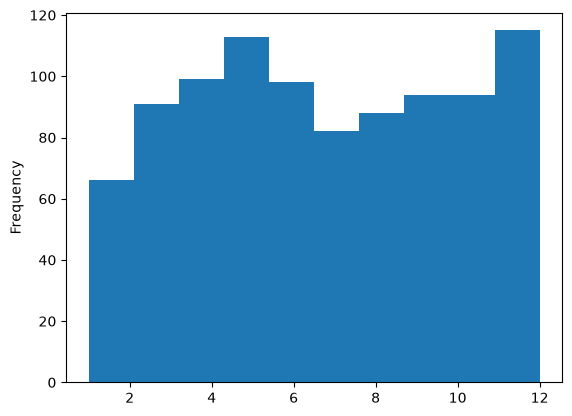

In [51]:
pd.to_datetime(daily_summary[daily_summary['qualifies']]['date']).dt.month.plot(kind = 'hist')

In [52]:
pd.to_datetime(daily_summary[daily_summary['qualifies']]['date']).dt.month.value_counts()

date
5     113
4      99
6      98
9      94
10     94
3      91
8      88
7      82
11     82
2      43
12     33
1      23
Name: count, dtype: int64

In [53]:
qualifying_winter_dates = daily_summary[
    (daily_summary["qualifies"])
    & (pd.to_datetime(daily_summary["date"]).dt.month == 1)
]
qualifying_winter_dates

,date,morning_peak_mw,morning_peak_kt,morning_peak_cf,morning_peak_sp,qualifies
737,2023-01-08,3163.000,1.500000,0.567188,0.225992,True
740,2023-01-11,3196.750,1.500000,0.573240,0.207552,True
756,2023-01-27,3044.000,1.256735,0.545849,0.206761,True
757,2023-01-28,3129.333,1.259205,0.561151,0.231931,True
1096,2024-01-02,3216.000,1.389053,0.474154,0.214970,True
1097,2024-01-03,3197.000,1.348566,0.471353,0.201296,True
1099,2024-01-05,3482.000,1.437811,0.513372,0.216493,True
1106,2024-01-12,3628.000,1.472950,0.534898,0.249348,True
1109,2024-01-15,3386.000,1.327571,0.499219,0.214768,True
1462,2025-01-02,3084.333,1.153590,0.400888,0.208422,True


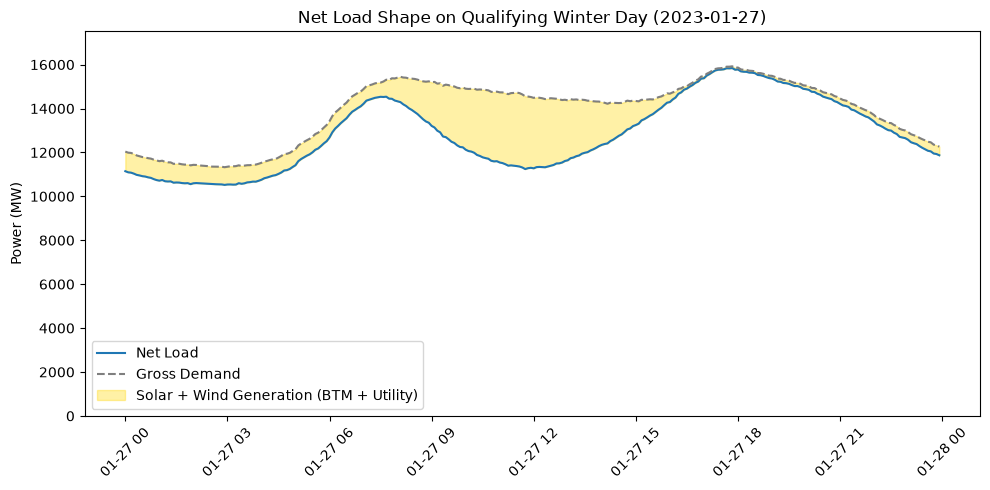

In [61]:


# Filter for a qualifying winter day (e.g., January 2024)
qualifying_winter_dates = daily_summary[
    (daily_summary["qualifies"])
    & (pd.to_datetime(daily_summary["date"]).dt.month == 1)
]
sample_date = qualifying_winter_dates.iloc[2]["date"]

sample_day = df[df["interval_start_local"].dt.date == sample_date]

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(
    sample_day["interval_start_local"],
    sample_day["net_load"],
    color="tab:blue",
    label="Net Load",
)
ax1.plot(
    
    sample_day["interval_start_local"],
    sample_day["gross_demand"],
    color="tab:gray",
    linestyle="--",
    label="Gross Demand",
)

ax1.fill_between(
    sample_day["interval_start_local"],
    sample_day["net_load"],
    sample_day["gross_demand"],
    color="gold",
    alpha=0.35,
    label="Solar + Wind Generation (BTM + Utility)",
)

y_max = sample_day["gross_demand"].max() * 1.10
ax1.set_ylim(bottom=0, top=y_max)
ax1.set_ylabel("Power (MW)")
ax1.set_title(f"Net Load Shape on Qualifying Winter Day ({sample_date})")
ax1.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


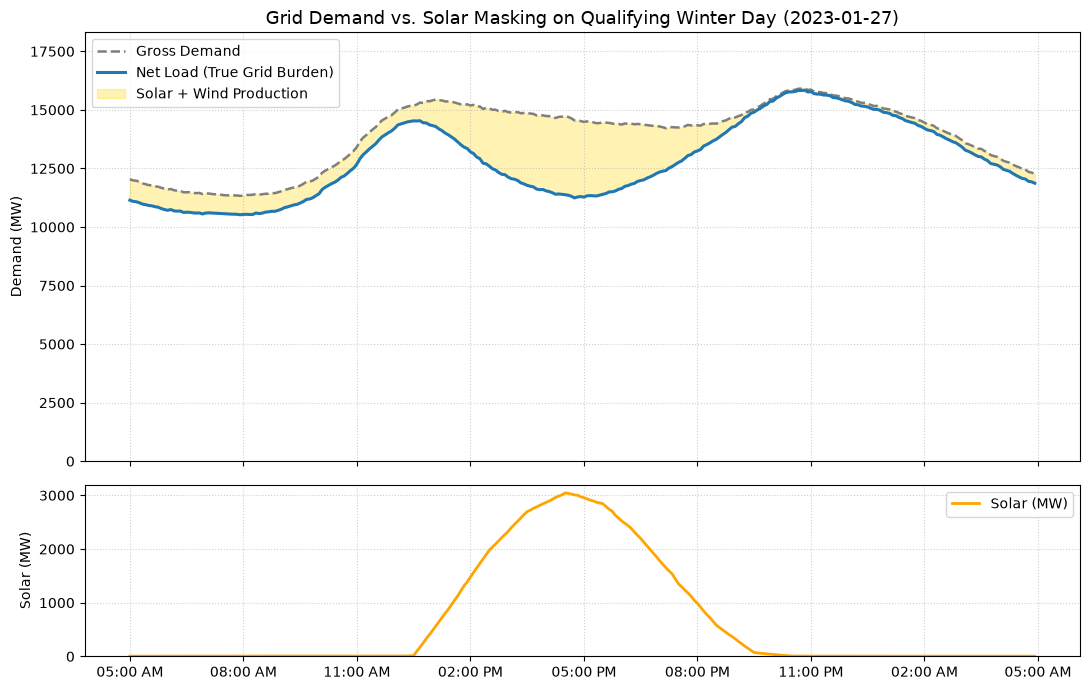

In [60]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]}
)

# Top Panel: Load Curves anchored at 0 MW
ax1.plot(
    sample_day["interval_start_local"],
    sample_day["gross_demand"],
    color="tab:gray",
    linestyle="--",
    linewidth=1.8,
    label="Gross Demand",
)
ax1.plot(
    sample_day["interval_start_local"],
    sample_day["net_load"],
    color="tab:blue",
    linewidth=2.2,
    label="Net Load (True Grid Burden)",
)
ax1.fill_between(
    sample_day["interval_start_local"],
    sample_day["net_load"],
    sample_day["gross_demand"],
    color="gold",
    alpha=0.3,
    label="Solar + Wind Production",
)

ax1.set_ylabel("Demand (MW)")
ax1.set_ylim(bottom=0, top=sample_day["gross_demand"].max() * 1.15)
ax1.set_title(
    f"Grid Demand vs. Solar Masking on Qualifying Winter Day ({sample_date})",
    fontsize=13,
)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle=":", alpha=0.6)

# Bottom Panel: Solar Production & Clear-Sky GHI
ax2.plot(
    sample_day["interval_start_local"],
    sample_day["total_solar"],
    color="orange",
    linewidth=2,
    label="Solar (MW)",
)
ax2.set_ylabel("Solar (MW)")
ax2.set_ylim(bottom=0)
ax2.legend(loc="upper right")
ax2.grid(True, linestyle=":", alpha=0.6)

# Format time axis
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%I:%M %p"))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



In [58]:
sample_day[['interval_start_local','utility_wind']]

,interval_start_local,utility_wind
217728,2023-01-27 00:00:00-05:00,888.0
217729,2023-01-27 00:05:00-05:00,890.5
217730,2023-01-27 00:10:00-05:00,893.0
217731,2023-01-27 00:15:00-05:00,888.0
217732,2023-01-27 00:20:00-05:00,879.5
...,...,...
218011,2023-01-27 23:35:00-05:00,408.0
218012,2023-01-27 23:40:00-05:00,408.0
218013,2023-01-27 23:45:00-05:00,400.0
218014,2023-01-27 23:50:00-05:00,392.0


In [79]:
def solar_pen_filter(telem_data, start_date='2021-01-01', end_date='2026-01-01', morning_peak_sp_thresh=0.20):
  """Filters for days where morning peak solar penetration exceeds threshold.

  Returns qualifying dates (or daily summary table).
  """
  data = telem_data

  data = data[data["interval_start_local"] >= pd.to_datetime(start_date).tz_localize('US/Eastern')]
  data = data[data["interval_start_local"] < pd.to_datetime(end_date).tz_localize('US/Eastern')]

  data = data.copy()
  data["total_solar"] = data["btm_solar"] + data["utility_solar"]
  expected_clear_cf = data["clearsky_ghi"] / 1000.0
  data["kt"] = (data["solar_capacity_factor"] / expected_clear_cf).clip(0, 1.5)
  data["solar_penetration"] = data["total_solar"] / data["gross_demand"]

  # Morning evaluation window: 10:00 AM to 12:00 PM Eastern
  morning_mask = (data["interval_start_local"].dt.hour >= 10) & (
      data["interval_start_local"].dt.hour < 12
  )
  morning_df = data[morning_mask].copy()
  morning_df["date"] = morning_df["interval_start_local"].dt.date

  daily_summary = (
      morning_df.groupby("date")
      .agg(
          morning_peak_mw=("total_solar", "max"),
          morning_peak_kt=("kt", "max"),
          morning_peak_cf=("solar_capacity_factor", "max"),
          morning_peak_sp=("solar_penetration", "max"),
      )
      .reset_index()
  )

  daily_summary["qualifies"] = (daily_summary["morning_peak_sp"] >= morning_peak_sp_thresh )

  print("Total days in window:", len(daily_summary))
  print(f"Qualifying days: {daily_summary['qualifies'].sum()} ({daily_summary['qualifies'].mean():.1%})" )

  return daily_summary[daily_summary["qualifies"]]["date"].reset_index(drop=True)


* **Objective**: Automatically detect the evening ramp on qualifying days and extract the clean 4-dimensional target vector.
- ✅ **Step 1**: Implement the **Event Qualification Gate** in `src/targets/qualify.py`. Days failing morning solar thresholds are flagged as non-ramp days and set aside.
* **Step 2**: Implement the **Astronomically Bounded Changepoint Detector** in `src/targets/segmenter.py`:
  * Apply the 35-minute Savitzky-Golay polynomial smoothing filter.
  * Window the search between solar zenith angle $\theta_z \ge 65^\circ$ and 10:00 PM local time.
  * Run the Pruned Exact Linear Time algorithm (PELT via `ruptures.Pelt`) using an $L_2$ piecewise cost (`cost="l2"`), minimum segment constraint (`min_size=6`, 30 minutes), and calibrated BIC penalty ($\beta = 2 \sigma^2 \ln(N)$).
  * Extract candidate changepoints, select the primary onset changepoint using slope thresholding, and enforce the 60-minute sustained rise condition.


In [86]:
d_days = solar_pen_filter(df)

df["date"] = df["interval_start_local"].dt.date
qualifying_set = set(d_days)  

df_qualify = df[df['date'].isin(qualifying_set)]

for date, day_data in df_qualify.groupby('date'):
    

Total days in window: 1826
Qualifying days: 940 (51.5%)


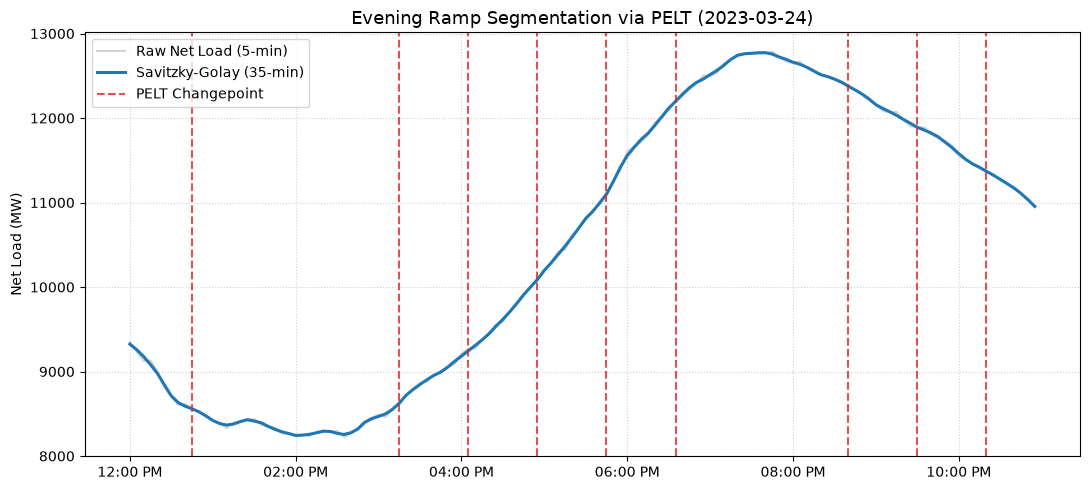

Detected Changepoints: ['12:45 PM', '03:15 PM', '04:05 PM', '04:55 PM', '05:45 PM', '06:35 PM', '08:40 PM', '09:30 PM', '10:20 PM']


In [97]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import ruptures as rpt
import scipy.signal as signal

# 1. Pick a strong qualifying day (e.g., March 24, 2023)
sample_date = pd.to_datetime("2023-03-24").date()
day_data = df[df["interval_start_local"].dt.date == sample_date].copy()

# 2. Window the candidate search:
# Afternoon only (after 12:00 PM), up to 10:00 PM, starting when sun reaches late angle (zenith >= 65°)
afternoon = day_data[
    (day_data["interval_start_local"].dt.hour >= 12)
    & (day_data["interval_start_local"].dt.hour <= 22)
]
search_start = afternoon[
    "interval_start_local"
].min()
window = afternoon[afternoon["interval_start_local"] >= search_start].copy()

# 3. Apply Savitzky-Golay smoothing (35-minute window = 7 points)
window["net_load_smooth"] = signal.savgol_filter(
    window["net_load"].values, window_length=7, polyorder=2
)
y = window["net_load_smooth"].values

# 4. Calibrate BIC-like penalty using MAD variance
diffs = np.diff(y)
mad = np.median(np.abs(diffs - np.median(diffs)))
sigma2 = (1.4826 * mad) ** 2
penalty = 10 * sigma2 * np.log(len(y))

# 5. Fit PELT changepoint detector
model = rpt.Pelt(model="l2", min_size=6).fit(y)
bkps = model.predict(pen=penalty)

# Extract changepoint timestamps (ruptures returns 1-indexed slice endpoints)
cp_indices = [idx - 1 for idx in bkps if idx < len(window)]
cp_times = window["interval_start_local"].iloc[cp_indices]


# 6. Plot the results
plt.figure(figsize=(11, 5))

x_plot = window["interval_start_local"].dt.tz_localize(None)
plt.plot(
    x_plot,
    window["net_load"],
    color="lightgray",
    linewidth=1.5,
    label="Raw Net Load (5-min)",
)
plt.plot(
    x_plot,
    window["net_load_smooth"],
    color="tab:blue",
    linewidth=2.2,
    label="Savitzky-Golay (35-min)",
)

# Overlay changepoints
for i, cp_time in enumerate(cp_times):
  plt.axvline(
      cp_time.tz_localize(None),
      color="tab:red",
      linestyle="--",
      alpha=0.8,
      label="PELT Changepoint" if i == 0 else "",
  )

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%I:%M %p"))
plt.title(f"Evening Ramp Segmentation via PELT ({sample_date})", fontsize=13)
plt.ylabel("Net Load (MW)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print(
    "Detected Changepoints:",
    [t.strftime("%I:%M %p") for t in cp_times.tolist()],
)


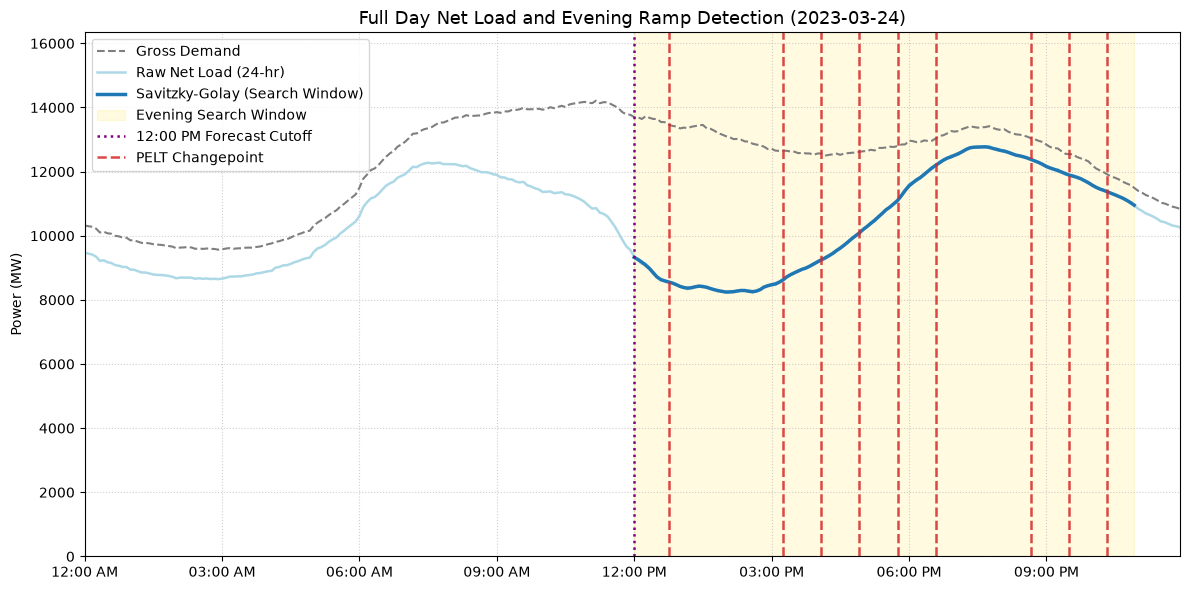

In [98]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# 1. Use the full 24-hour day for the base plot (naive local time for plotting)
x_full = day_data["interval_start_local"].dt.tz_localize(None)
x_window = window["interval_start_local"].dt.tz_localize(None)

plt.figure(figsize=(12, 6))

# Full-day Gross Demand and Net Load (zero-anchored)
plt.plot(
    x_full,
    day_data["gross_demand"],
    color="tab:gray",
    linestyle="--",
    linewidth=1.5,
    label="Gross Demand",
)
plt.plot(
    x_full,
    day_data["net_load"],
    color="lightblue",
    linewidth=1.8,
    label="Raw Net Load (24-hr)",
)

# Smoothed line over the evening search window
plt.plot(
    x_window,
    window["net_load_smooth"],
    color="tab:blue",
    linewidth=2.5,
    label="Savitzky-Golay (Search Window)",
)

# Optional: Highlight the candidate search window (Zenith >= 65° to 10:00 PM)
plt.axvspan(
    x_window.iloc[0],
    x_window.iloc[-1],
    color="gold",
    alpha=0.12,
    label="Evening Search Window",
)

# Mark the 12:00 PM Forecast Cutoff
noon_time = pd.Timestamp(f"{sample_date} 12:00")
plt.axvline(
    noon_time,
    color="purple",
    linestyle=":",
    linewidth=1.8,
    label="12:00 PM Forecast Cutoff",
)

# Overlay the PELT changepoints
for i, cp_time in enumerate(cp_times):
  plt.axvline(
      cp_time.tz_localize(None),
      color="tab:red",
      linestyle="--",
      linewidth=1.8,
      alpha=0.85,
      label="PELT Changepoint" if i == 0 else "",
  )

# Formatting
plt.ylim(bottom=0, top=day_data["gross_demand"].max() * 1.15)
plt.xlim(
    pd.Timestamp(f"{sample_date} 00:00"), pd.Timestamp(f"{sample_date} 23:55")
)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%I:%M %p"))
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=3))

plt.title(
    f"Full Day Net Load and Evening Ramp Detection ({sample_date})", fontsize=13
)
plt.ylabel("Power (MW)")
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


In [101]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as signal

#Filter afternoon search window (12:00 PM up to 10:00 PM)
afternoon = day_data[
    (day_data["interval_start_local"].dt.hour >= 12) & (day_data["interval_start_local"].dt.hour <= 22)
]
search_start = afternoon["interval_start_local"].min()
window = afternoon[afternoon["interval_start_local"] >= search_start]

# Savitzky-Golay smoothing (35-min window = 7 intervals)
window["net_load_smooth"] = signal.savgol_filter(window["net_load"].values, window_length=7, polyorder=2)
y = window["net_load_smooth"].values
times = window["interval_start_local"].values

# Identify Ramp Peak (t_peak)
peak_idx = int(np.argmax(y))
t_peak = window["interval_start_local"].iloc[peak_idx]

# Identify Ramp Start (t_start):
# Earliest inflection before peak where slope is >= 5 MW/min and sustained for 60 min (12 steps)
start_idx = 0
for i in range(len(y) - 12):
  slope_30m = (y[min(i + 6, len(y) - 1)] - y[i]) / 30.0  # MW per minute
  sustained = np.mean(y[i + 1 : i + 13]) > y[i]  # 60-min sustained rise

  if slope_30m >= 5.0 and sustained and i < peak_idx:
    start_idx = i
    break

t_start = window["interval_start_local"].iloc[start_idx]

# Calculate the  Target Vector
noon_ref = pd.Timestamp(f"{sample_date} 12:00", tz="US/Eastern")
t_start_minutes = (t_start - noon_ref).total_seconds() / 60.0
delta_t_minutes = (t_peak - t_start).total_seconds() / 60.0

delta_mw_raw = window["net_load"].iloc[peak_idx] - window["net_load"].iloc[start_idx]
solar_cap = window["TOTAL_SOLAR_CAPACITY_MW"].iloc[start_idx]
delta_mw_norm = delta_mw_raw / solar_cap

# Max 5-minute ramp speed during the event (MW/min)
ramp_segment = window["net_load"].iloc[start_idx : peak_idx + 1].values
s_max = np.max(np.diff(ramp_segment) / 5.0)

# Display Target Vector
print("=" * 45)
print(f"TARGET VECTOR FOR {sample_date}")
print("=" * 45)
print(f"1. Ramp Start (t_start) : {t_start.strftime('%I:%M %p')} ({t_start_minutes:.0f} min past noon)")
print(f"2. Normalized Mag (ΔMW) : {delta_mw_norm:.3f} (Raw: +{delta_mw_raw:.0f} MW across {solar_cap:.0f} MW fleet)")
print(f"3. Duration (Δt)        : {delta_t_minutes:.0f} min ({delta_t_minutes/60:.1f} hours)")
print(f"4. Peak Speed (S_max)   : {s_max:.1f} MW/min")
print("=" * 45)


TARGET VECTOR FOR 2023-03-24
1. Ramp Start (t_start) : 02:30 PM (150 min past noon)
2. Normalized Mag (ΔMW) : 0.773 (Raw: +4463 MW across 5776 MW fleet)
3. Duration (Δt)        : 310 min (5.2 hours)
4. Peak Speed (S_max)   : 43.7 MW/min


In [147]:
def plot_day(day_data, targets=None):
  # If targets not passed, extract them directly
  if targets is None:
    targets = extract_ramp_targets(day_data)

  # Isolate local timestamps and day limits
  t_day = day_data["interval_start_local"].iloc[0]
  sample_date = t_day.strftime("%Y-%m-%d")
  day_start = pd.Timestamp(f"{sample_date} 00:00")
  day_end = pd.Timestamp(f"{sample_date} 23:55")

  x_full = day_data["interval_start_local"].dt.tz_localize(None)

  # Filter afternoon window for smoothed net load
  afternoon = day_data[
      (day_data["interval_start_local"].dt.hour >= 12)
      & (day_data["interval_start_local"].dt.hour <= 22)
  ].copy()
  net_load_smooth = signal.savgol_filter(
      afternoon["net_load"].values, window_length=7, polyorder=2
  )
  x_afternoon = afternoon["interval_start_local"].dt.tz_localize(None)

  # Naive timestamps for vertical markers
  t_start_naive = targets["t_start_local"].tz_localize(None)
  t_peak_naive = targets["t_peak_local"].tz_localize(None)

  plt.figure(figsize=(12, 6))

  # Full day gross demand and net load
  plt.plot(
      x_full,
      day_data["gross_demand"],
      color="tab:gray",
      linestyle="--",
      label="Gross Demand",
  )
  plt.plot(
      x_full,
      day_data["net_load"],
      color="lightblue",
      linewidth=1.8,
      label="Net Load",
  )
  plt.plot(
      x_afternoon,
      net_load_smooth,
      color="tab:blue",
      linewidth=2.5,
      label="Smoothed Net Load",
  )

  # Highlight detected ramp event
  plt.axvspan(
      t_start_naive,
      t_peak_naive,
      color="orange",
      alpha=0.2,
      label=f"Detected Ramp ({targets['delta_t_min']:.0f} min)",
  )
  plt.axvline(
      t_start_naive,
      color="green",
      linewidth=2.2,
      linestyle="-",
      label=f"Ramp Start ({targets['t_start_local'].strftime('%I:%M %p')})",
  )
  plt.axvline(
      t_peak_naive,
      color="red",
      linewidth=2.2,
      linestyle="-",
      label=f"Ramp Peak ({targets['t_peak_local'].strftime('%I:%M %p')})",
  )

  # Strict 24-hour limits and styling
  plt.xlim(day_start, day_end)
  plt.ylim(bottom=0, top=day_data["gross_demand"].max() * 1.15)
  plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%I:%M %p"))
  plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=3))

  plt.title(
      f"Ramp Envelope & Target Detection ({sample_date})", fontsize=13
  )
  plt.ylabel("Power (MW)")
  plt.legend(loc="upper left")
  plt.grid(True, linestyle=":", alpha=0.6)
  plt.tight_layout()
  plt.show()


In [250]:
def extract_ramp_targets(day_data):
    """Apply Savitzky-Golay smoothing and then extract ramp start, duration, amplitude, peak_change (s_max)"""    
    #Filter afternoon search window (12:00 PM up to 10:00 PM)
    afternoon = day_data[
        (day_data["interval_start_local"].dt.hour >= 12) & (day_data["interval_start_local"].dt.hour <= 22)
    ].copy()
    
    
    # Interpolate isolated missing telemetry intervals (e.g. 1-2 intervals)
    afternoon["net_load"] = (afternoon["net_load"].interpolate(method="linear").bfill().ffill())
    if afternoon['net_load'].isna().any(): return None

    # Savitzky-Golay smoothing (35-min window = 7 intervals)
    afternoon["net_load_smooth"] = signal.savgol_filter(afternoon["net_load"].values, window_length=7, polyorder=2)
    y = afternoon["net_load_smooth"].values
    times = afternoon["interval_start_local"].values
    
    # Identify solar peak and 10% decay threshold
    peak_solar_val = day_data["solar_capacity_factor"].max()
    peak_solar_idx = day_data["solar_capacity_factor"].idxmax()
    # Filter for timestamps after solar peak where CF drops to <= 90% of peak
    post_peak_data = day_data.loc[peak_solar_idx:]
    decay_candidates = post_peak_data[
        post_peak_data["solar_capacity_factor"] <= 0.90 * peak_solar_val
    ]
    if not decay_candidates.empty:
        t_decay = decay_candidates["interval_start_local"].min()
    else:
        t_decay = day_data.loc[peak_solar_idx, "interval_start_local"]

    # Identify Ramp Peak (t_peak)
    peak_idx = int(np.argmax(y))
    t_peak = afternoon["interval_start_local"].iloc[peak_idx]

     # Find index in afternoon corresponding to t_decay
    decay_idx = 0
    for idx, t in enumerate(afternoon["interval_start_local"]):
        if t >= t_decay:
            decay_idx = idx
            break

    decay_idx = min(decay_idx, peak_idx)

    # Initialize start_idx to net load trough from decay_idx up to peak_idx
    start_idx = decay_idx + int(np.argmin(y[decay_idx:peak_idx])) if decay_idx < peak_idx else decay_idx

    # Identify Ramp Start (t_start):
    # Earliest inflection before peak where slope is >= 5 MW/min and sustained for 60 min (12 steps)

    for i in range(start_idx, len(y) - 12):
        slope_30m = (y[min(i + 6, len(y) - 1)] - y[i]) / 30.0  # MW per minute
        sustained = np.mean(y[i + 1 : i + 13]) > y[i]  # 60-min sustained rise

        if slope_30m >= 5.0 and sustained and i < peak_idx:
            start_idx = i
            break

    t_start = afternoon["interval_start_local"].iloc[start_idx]

    # Calculate the  Target Vector
    noon_ref = afternoon["interval_start_local"].iloc[0].replace(hour = 12, minute = 0, second = 0)
    t_start_minutes = (t_start - noon_ref).total_seconds() / 60.0
    delta_t_minutes = (t_peak - t_start).total_seconds() / 60.0

    delta_mw_raw = afternoon["net_load"].iloc[peak_idx] - afternoon["net_load"].iloc[start_idx]
    solar_cap = afternoon["TOTAL_SOLAR_CAPACITY_MW"].iloc[start_idx]
    delta_mw_norm = delta_mw_raw / solar_cap

    # Max 5-minute ramp speed during the event (MW/min)
    ramp_segment = afternoon["net_load_smooth"].iloc[start_idx : peak_idx + 1].values
    s_max = np.max(np.diff(ramp_segment) / 5.0)

    total_solar_capacity_mw = afternoon['TOTAL_SOLAR_CAPACITY_MW'].max()
    
    # Disqualify days where peak is not in the evening or ramp is too brief
    if t_peak.hour < 16 or delta_t_minutes < 120:
        return None

    return {
        "date": afternoon['interval_start_utc'].iloc[0].date(),
        "t_start_min": t_start_minutes,
        "delta_t_min": delta_t_minutes,
        "delta_mw_norm": delta_mw_norm,
        "s_max": s_max,
        "t_start_local": t_start,
        "t_peak_local": t_peak,
        "delta_mw_raw" : delta_mw_raw,
        "total_solar_capacitY_mw" : total_solar_capacity_mw
    }


In [251]:
d = df[df["interval_start_local"].dt.date == pd.to_datetime("2025-07-25").date()]
extract_ramp_targets(d)

In [252]:
plot_day(d)

TypeError: 'NoneType' object is not subscriptable

In [253]:
qualifying_dates = set(solar_pen_filter(df))
df_qual = df[df["interval_start_local"].dt.date.isin(qualifying_dates)].copy()

target_records = []
for date, day_df in df_qual.groupby(df_qual["interval_start_local"].dt.date):
  result = extract_ramp_targets(day_df)
  if result is not None:
    target_records.append(result)
targets_df = pd.DataFrame(target_records)


Total days in window: 1826
Qualifying days: 940 (51.5%)


t_start_min


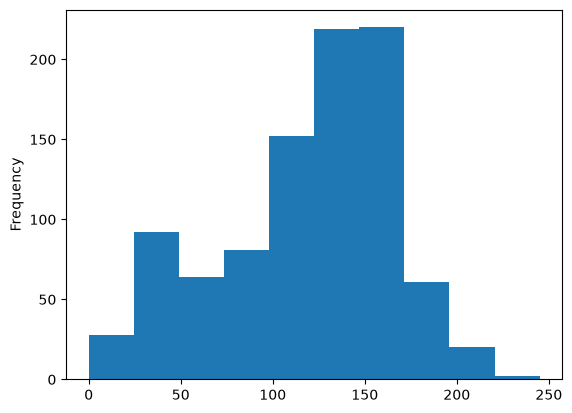

delta_t_min


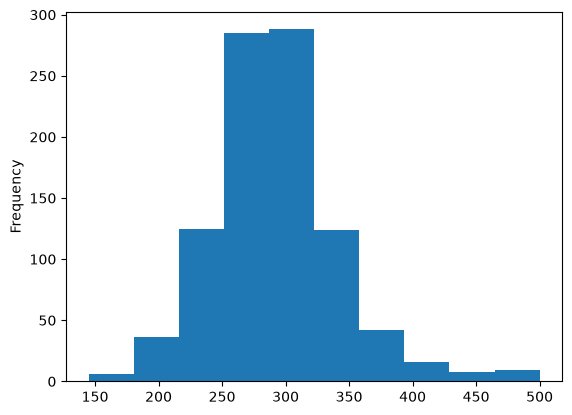

delta_mw_norm


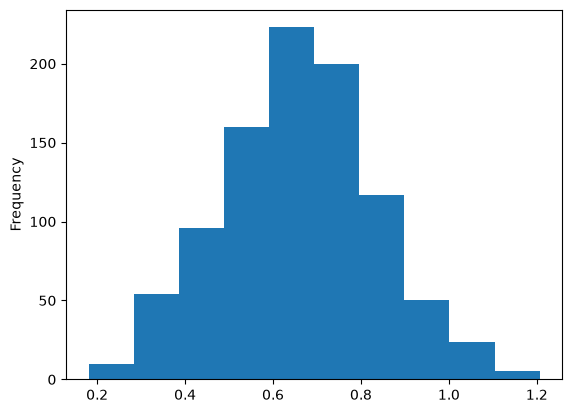

s_max


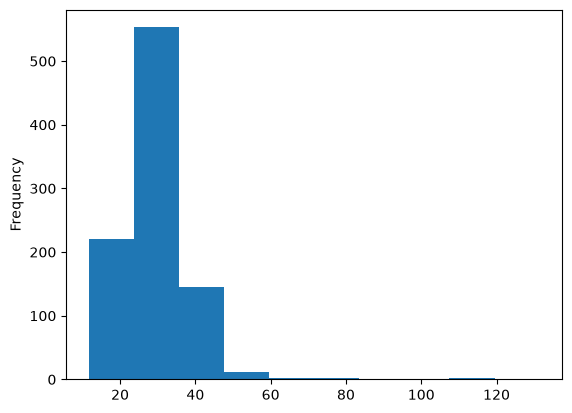

t_start_local


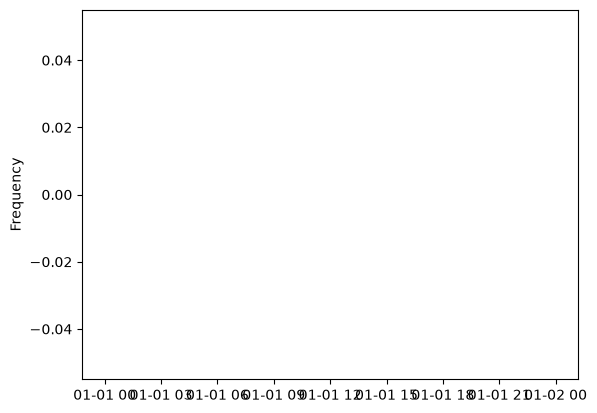

t_peak_local


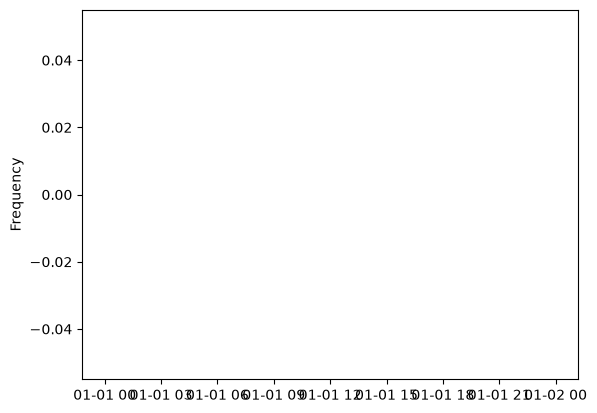

In [254]:
for col in ['t_start_min', 'delta_t_min', 'delta_mw_norm', 's_max','t_start_local', 't_peak_local']:
    print(col)
    targets_df[col].plot(kind='hist')
    plt.show()

In [255]:
targets_df[targets_df['t_start_min'] <5].iloc[8]

date                                      2025-01-19
t_start_min                                      0.0
delta_t_min                                    335.0
delta_mw_norm                               0.592212
s_max                                      23.458381
t_start_local              2025-01-19 12:00:00-05:00
t_peak_local               2025-01-19 17:35:00-05:00
delta_mw_raw                                4556.328
total_solar_capacitY_mw                  7693.745205
Name: 704, dtype: object

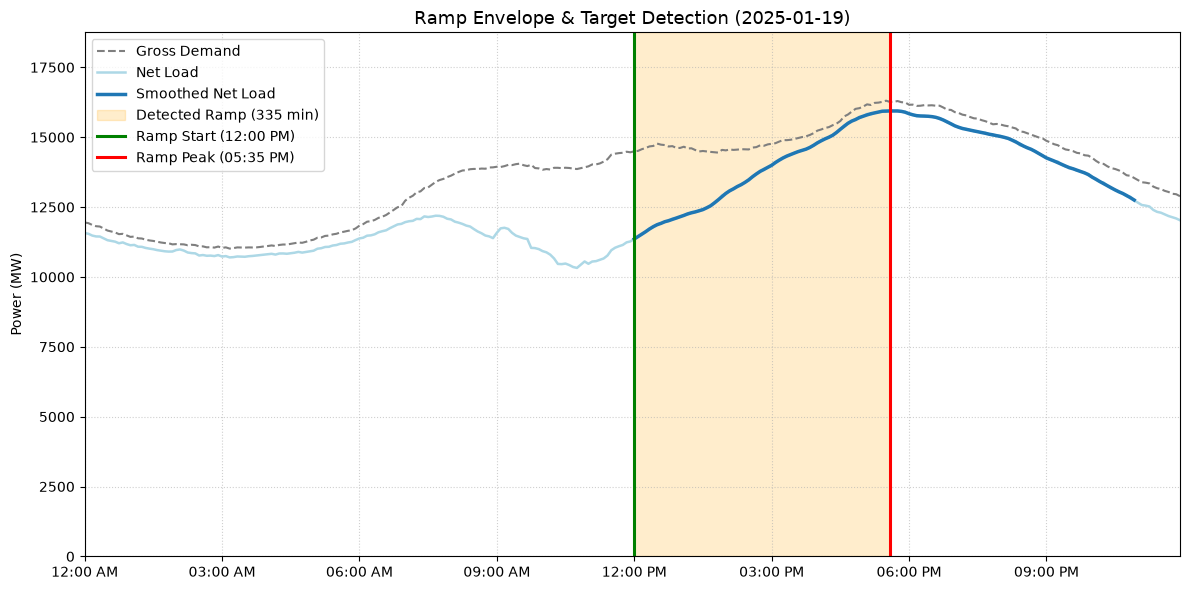

In [256]:
sample_early_ramp = targets_df[targets_df['t_start_min'] <5].iloc[8]['t_start_local']
d2 = df[df["interval_start_local"].dt.date == sample_early_ramp.date()]

plot_day(d2)

In [257]:
targets_df[targets_df['t_start_min'] <10]['t_start_local'].dt.month.value_counts()

t_start_local
5     4
11    4
3     2
12    2
4     2
1     1
Name: count, dtype: int64

In [258]:
assert targets_df.isna().sum().sum() == 0, "Found null values in targets!"
assert np.isfinite(
    targets_df.select_dtypes(include=[np.number])
).all().all(), "Found infinite values!"

assert targets_df["date"].nunique() == len(targets_df), "Found duplicate dates!"
assert targets_df["date"].is_monotonic_increasing, (
    "Target dates are not sorted chronologically!"
)

print(
    f"Covered {len(targets_df)} of {len(qualifying_dates)} qualifying days"
    f" ({len(targets_df)/len(qualifying_dates):.1%})"
)


Covered 939 of 940 qualifying days (99.9%)


In [259]:
s_avg = targets_df["delta_mw_raw"] / targets_df["delta_t_min"]
violations = (targets_df["s_max"] < s_avg).sum()
assert violations == 0, (
    f"Physical violation: S_max < S_avg on {violations} days!"
)

# Duration between 2 and 9 hours (120 to 540 min)
assert (targets_df["delta_t_min"] > 120).all() and (
    targets_df["delta_t_min"] < 600
).all()

# Normalized magnitude is positive and physically realistic
assert (targets_df["delta_mw_norm"] > 0.1).all() and (
    targets_df["delta_mw_norm"] < 1.5
).all()

# Peak occurred strictly after ramp onset
assert (targets_df["t_peak_local"] > targets_df["t_start_local"]).all()


In [260]:
targets_df[
    ~((targets_df["delta_t_min"] > 120) & (targets_df["delta_t_min"] < 600))
]

,date,t_start_min,delta_t_min,delta_mw_norm,s_max,t_start_local,t_peak_local,delta_mw_raw,total_solar_capacitY_mw


In [261]:
targets_df["year"] = pd.to_datetime(targets_df["date"]).dt.year
yearly = targets_df.groupby("year").agg(
    days=("date", "count"),
    raw_mw_mean=("delta_mw_raw", "mean"),
    norm_mw_mean=("delta_mw_norm", "mean"),
    norm_mw_std=("delta_mw_norm", "std"),
    s_max_mean=("s_max", "mean"),
)
print(yearly.round(2))


      days  raw_mw_mean  norm_mw_mean  norm_mw_std  s_max_mean
year                                                          
2021    66      3492.21          0.81         0.19       24.97
2022   165      3719.55          0.72         0.17       26.23
2023   209      4025.45          0.66         0.19       26.68
2024   255      4517.44          0.63         0.16       31.51
2025   244      4978.04          0.62         0.15       33.40


In [262]:
targets_df.to_parquet("data/processed/daily_ramp_targets.parquet", index=False)
print("Saved daily_ramp_targets.parquet successfully.")


Saved daily_ramp_targets.parquet successfully.


In [263]:
len(targets_df)

939